<a href="https://colab.research.google.com/github/HariniRJ/ai-lab/blob/main/FOL_WEEK_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- First-Order Logic Forward Chaining Graphical Tool ---
Enter rules/facts line by line. Type 'DONE' when finished.

KB entry> Fever(p)
  Added: Fever(p)
KB entry> SoreThroat(p)
  Added: SoreThroat(p)
KB entry> MuscleAches(p)
  Added: MuscleAches(p)
KB entry> Fever(x) ^ SoreThroat(x) => InfectionSigns(x)
  Added: (Fever(x) ^ SoreThroat(x) => InfectionSigns(x))
KB entry> InfectionSigns(x) ^ MuscleAches(x) => TestFlu(x)
  Added: (InfectionSigns(x) ^ MuscleAches(x) => TestFlu(x))
KB entry> DONE

Knowledge Base generated successfully.
Enter your Query atom: TestFlu(p)

Running FOL-FC-ASK for query: TestFlu(p)...
Execution Result: {}

[Display Window]: Opening graph canvas pop-up window...


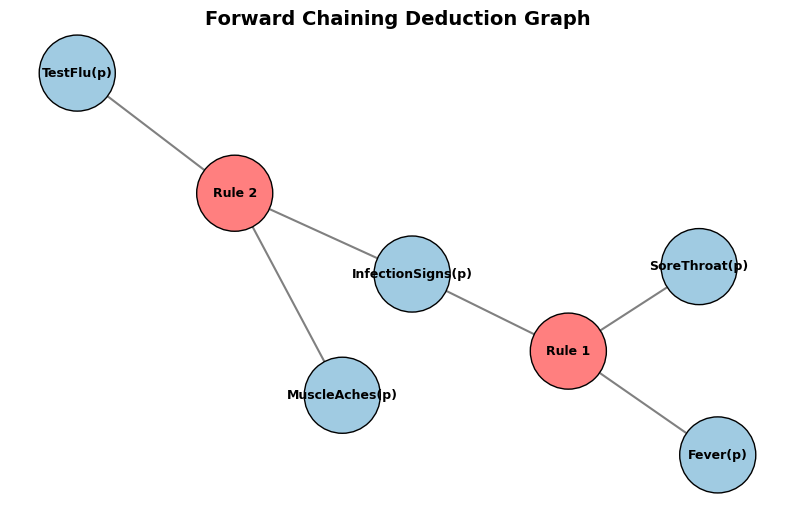

In [9]:
import copy
import sys
import re

# Try importing graph plotting libraries
try:
    import networkx as nx
    import matplotlib.pyplot as plt
except ImportError:
    print("[Error]: This script requires networkx and matplotlib libraries.")
    print("Please install them using: pip install networkx matplotlib")
    sys.exit(1)

class Expr:
    def __init__(self, op, *args):
        self.op = op
        self.args = list(args)

    def __repr__(self):
        if self.op == '=>':
            antecedents = " ^ ".join(map(str, self.args[0]))
            return f"({antecedents} => {self.args[1]})"
        if not self.args:
            return str(self.op)
        return f"{self.op}({', '.join(map(str, self.args))})"

    def __eq__(self, other):
        return isinstance(other, Expr) and self.op == other.op and self.args == other.args

def is_variable(x):
    return isinstance(x, str) and x.islower() and len(x) >= 1

_var_counter = 0

def standardize_variables(rule):
    global _var_counter
    var_map = {}

    def collect_vars(expr):
        if is_variable(expr):
            if expr not in var_map:
                global _var_counter
                _var_counter += 1
                var_map[expr] = f"{expr}_{_var_counter}"
            return var_map[expr]
        if isinstance(expr, Expr):
            if expr.op == '=>':
                new_antecedents = [Expr(p.op, *[collect_vars(a) for a in p.args]) for p in expr.args[0]]
                new_consequent = Expr(expr.args[1].op, *[collect_vars(a) for a in expr.args[1].args])
                return Expr('=>', new_antecedents, new_consequent)
            else:
                return Expr(expr.op, *[collect_vars(a) for a in expr.args])
        return expr

    return collect_vars(rule)

def subst(theta, expr):
    if is_variable(expr):
        return theta.get(expr, expr)
    if isinstance(expr, Expr):
        if expr.op == '=>':
            return Expr('=>', [subst(theta, p) for p in expr.args[0]], subst(theta, expr.args[1]))
        return Expr(expr.op, *[subst(theta, arg) for arg in expr.args])
    return expr

def unify(x, y, theta=None):
    if theta is None:
        theta = {}
    if theta is False:
        return False
    elif x == y:
        return theta
    elif is_variable(x):
        return unify_var(x, y, theta)
    elif is_variable(y):
        return unify_var(y, x, theta)
    elif isinstance(x, Expr) and isinstance(y, Expr):
        if x.op != y.op or len(x.args) != len(y.args):
            return False
        for ax, ay in zip(x.args, y.args):
            theta = unify(ax, ay, theta)
        return theta
    elif isinstance(x, list) and isinstance(y, list):
        if len(x) != len(y):
            return False
        for ax, ay in zip(x, y):
            theta = unify(ax, ay, theta)
        return theta
    else:
        return False

def unify_var(var, x, theta):
    if var in theta:
        return unify(theta[var], x, theta)
    elif is_variable(x) and x in theta:
        return unify(var, theta[x], theta)
    new_theta = copy.deepcopy(theta)
    new_theta[var] = x
    return new_theta

def find_all_substitutions(antecedents, kb, theta=None):
    if theta is None:
        theta = {}
    if not antecedents:
        yield theta
        return

    first, rest = antecedents[0], antecedents[1:]
    for fact in kb:
        if fact.op != '=>':
            t = unify(first, fact, theta)
            if t is not False:
                yield from find_all_substitutions(rest, kb, t)

graph_history = []

def fol_fc_ask(kb, alpha):
    global graph_history
    graph_history = []
    rule_counters = {}

    while True:
        new = []
        rules = [sentence for sentence in kb if sentence.op == '=>']

        for rule in rules:
            standard_rule = standardize_variables(rule)
            p_list, q = standard_rule.args[0], standard_rule.args[1]

            for theta in find_all_substitutions(p_list, kb):
                q_prime = subst(theta, q)
                already_exists = any(unify(q_prime, fact) is not False for fact in kb + new)

                if not already_exists:
                    new.append(q_prime)

                    matched_premises = []
                    for p in p_list:
                        substituted_p = subst(theta, p)
                        for fact in kb:
                            if unify(substituted_p, fact) is not False:
                                matched_premises.append(str(fact))
                                break

                    rule_text = f"IF {' ^ '.join(map(str, rule.args[0]))} THEN {rule.args[1]}"
                    if rule_text not in rule_counters:
                        rule_counters[rule_text] = len(rule_counters) + 1
                    rule_label = f"Rule {rule_counters[rule_text]}"

                    graph_history.append({
                        'premises': list(set(matched_premises)),
                        'rule': rule_label,
                        'conclusion': str(q_prime)
                    })

                    phi = unify(q_prime, alpha)
                    if phi is not False:
                        return phi

        if not new:
            break
        kb.extend(new)
    return False

def render_library_graph():
    if not graph_history:
        print("\n[Graph Error]: No paths found to draw.")
        return

    G = nx.DiGraph()

    for step in graph_history:
        rule_node = step['rule']
        conclusion_node = step['conclusion']

        G.add_node(rule_node, type='rule')
        G.add_node(conclusion_node, type='fact')

        for p in step['premises']:
            G.add_node(p, type='fact')
            G.add_edge(p, rule_node)

        G.add_edge(rule_node, conclusion_node)

    plt.figure(figsize=(10, 6))
    plt.title("Forward Chaining Deduction Graph", fontsize=14, fontweight='bold')

    pos = nx.spring_layout(G, seed=42)

    node_colors = []
    for node in G.nodes():
        if G.nodes[node].get('type') == 'rule':
            node_colors.append('#ff7f7f')
        else:
            node_colors.append('#a0cbe2')

    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=3000, edgecolors='black')
    nx.draw_networkx_edges(G, pos, arrowstyle='->', arrowsize=20, edge_color='gray', width=1.5)
    nx.draw_networkx_labels(G, pos, font_size=9, font_weight='bold')

    plt.axis('off')
    print("\n[Display Window]: Opening graph canvas pop-up window...")
    plt.show()

# ==================== TERMINAL PARSER ====================

def parse_atom(text):
    text = text.strip()
    # Automatically strip any leading numerical labels (e.g. "3. MuscleAches" -> "MuscleAches")
    text = re.sub(re.compile(r'^\d+\.\s*'), '', text)

    if '(' not in text:
        return Expr(text)
    op, args_str = text.split('(', 1)
    args_str = args_str.rstrip(')')
    args = [arg.strip() for arg in args_str.split(',') if arg.strip()]
    return Expr(op.strip(), *args)

def parse_line(line):
    line = line.strip()
    if '=>' in line:
        antecedent_str, consequent_str = line.split('=>', 1)
        antecedents = [parse_atom(p) for p in antecedent_str.split('^')]
        consequent = parse_atom(consequent_str)
        return Expr('=>', antecedents, consequent)
    else:
        return parse_atom(line)

if __name__ == "__main__":
    print("--- First-Order Logic Forward Chaining Graphical Tool ---")
    print("Enter rules/facts line by line. Type 'DONE' when finished.\n")

    kb = []
    while True:
        entry = input("KB entry> ").strip()
        if entry.upper() == 'DONE':
            break
        if not entry:
            continue
        try:
            parsed = parse_line(entry)
            kb.append(parsed)
            print(f"  Added: {parsed}")
        except Exception as e:
            print(f"  Parsing Error: {e}")

    print("\nKnowledge Base generated successfully.")
    query_str = input("Enter your Query atom: ").strip()

    try:
        query = parse_atom(query_str)
        print(f"\nRunning FOL-FC-ASK for query: {query}...")
        result = fol_fc_ask(kb, query)
        print(f"Execution Result: {result}")

        if result is not False:
            render_library_graph()

    except Exception as e:
        print(f"Execution error: {e}")
